# Ramsey inference with Qiskit 2
## A fictional three-minute superconducting-qubit monitoring session

A qubit was calibrated against a reference at the start of a session. Its resonance drifts by several kilohertz as the lab repeatedly measures Ramsey fringes. The goal is to estimate the current detuning and forecast the phase of a target operation executed several seconds later.

This notebook implements the proposal's paired-quadrature design and exact binomial likelihood. It follows **one evolving trajectory**. Each shot prepares a fresh qubit, while shots in a short block share the same latent detuning. The experiment uses illustrative device parameters and requires no credentials.

**Run all cells.** Edit the first configuration cell to change the experiment. The analytic path draws exact binomial counts under the stated circuit model. With Qiskit 2 and Aer installed, the same lab can generate those counts by running circuits.

## 1. What goes into the experiment

| Quantity | Who supplies it? | What it does |
|---|---|---|
| Interrogation times, phases, shots per setting and block spacing | Researcher | Determines where and how often the qubit is observed |
| Timing overhead, prediction horizon and target wait | Researcher | Determines acquisition time and the target phase to predict |
| Calibration reference and number of calibration shots | Researcher | Defines separate basis-state and contrast calibration experiments |
| Counts from prepared basis states, calibration fringes and monitoring fringes | Simulator or experiment | The observations available to analysis |
| Frequency search range, initial prior and assumed correlation time | Analyst | Working assumptions for inference |
| Actual detuning trajectory, assignment errors and coherence parameters | Simulator only | Generates observations and provides truth for scoring |

The scientist specifies a fixed protocol. They do not specify the actual detuning at each time or the measurement outcomes. The modeler specifies assumptions about the drift and prior range, distinct from the simulator's generating process. Changing the prior can change which alias receives the most posterior mass.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from scipy.special import logsumexp, xlogy
from scipy.stats import norm

# Researcher controls. Time units appear in each parameter name.
waits_us = (30., 120.)
phases_rad = (0., -np.pi/2)
shots = 96                  # per setting, per block
blocks, block_spacing_s = 96, 2.
overhead_us = 280.          # preparation, measurement and repetition time
readout_shots = 1500        # per prepared basis state
fringe_shots = 800          # per calibration wait and phase
cal_waits_us = (0., 20., 50., 90., 140., 200.)
forecast_blocks, target_wait_us = 3, 100.

# Analyst controls. These are the working prior and transition parameters.
grid_limit_hz, grid_points = 16000., 321
prior_sd_hz = 6000.
correlation_time_s, stationary_sd_hz = 70., 4200.

# Reproducibility and simulator choice.
seed = 2026
engine = "auto"             # auto, analytic, or aer
assert 0 < forecast_blocks < blocks
assert min(waits_us) > 0 and shots > 0 and block_spacing_s > 0
assert overhead_us >= 0 and target_wait_us > 0
assert readout_shots > 0 and fringe_shots > 0
assert min(cal_waits_us) >= 0 and len(set(cal_waits_us)) >= 2
assert grid_points > 2 and min(grid_limit_hz,prior_sd_hz,correlation_time_s,stationary_sd_hz)>0

## 2. The circuit and the clock

The circuit is $H$, accumulated phase $R_z(2\pi f\tau)$, analysis phase $R_z(\phi)$, $H$, and measurement. Here $f$ is in Hz and $\tau$ is in seconds. The probability of the final ideal **zero** is $\{1+\cos(2\pi f\tau+\phi)\}/2$. Phase zero gives the cosine and phase $-\pi/2$ gives the sine. A positive small detuning therefore raises the zero probability in the sine channel before readout error.

An effective contrast $c(\tau)=c_0\exp(-\tau/T_2^*)$ multiplies the fringe. The Aer implementation uses a phase damping parameter $1-c^2$, because the channel scales transverse coherence by $\sqrt{1-\gamma}$. Assignment errors $e_0=P(1_{\rm obs}\mid0)$ and $e_1=P(0_{\rm obs}\mid1)$ give
$$
p_{0,\rm obs}(f)=e_1+(1-e_0-e_1)\{1+c(\tau)\cos(2\pi f\tau+\phi)\}/2.
$$

The model implements free evolution through a rotation and the effective envelope. The same wait is charged in a separate timing ledger, along with a fixed overhead per shot. Settings are acquired sequentially. The ledger records their midpoints and verifies that a block fits within its assigned interval. The binomial calculation then uses a shared frequency within each block. If the detuning changes appreciably while acquiring a block, use actual shot times and individual probabilities.

In [2]:
try:
    from qiskit import QuantumCircuit, transpile
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, ReadoutError, phase_damping_error
    aer_available = True
except ImportError:
    aer_available = False

if engine not in {"auto", "analytic", "aer"}:
    raise ValueError("Choose auto, analytic, or aer.")
if engine == "aer" and not aer_available:
    raise ImportError("Install Qiskit 2 and qiskit-aer in this notebook kernel.")
use_aer = aer_available and engine != "analytic"
settings = [(t*1e-6, phi) for t in waits_us for phi in phases_rad]
waits, phases = np.array(settings).T
times = np.arange(blocks) * block_spacing_s
duration = shots * (waits + overhead_us*1e-6)
assert duration.sum() < block_spacing_s, "Settings do not fit in the block."
setting_time_s = times[:,None] + (np.cumsum(duration)-duration/2)[None,:]
print(f"{len(settings)*shots} shots per block; {1000*duration.sum():.1f} ms active time.")
print("Engine:", "Qiskit Aer" if use_aer else "analytic binomial simulator")

def p_zero(f, wait, phi, calibration):
    e0,e1,c0,t2 = calibration
    contrast = c0*np.exp(-wait/t2)
    return e1+(1-e0-e1)*(1+contrast*np.cos(2*np.pi*f*wait+phi))/2

def ramsey_circuit(f, wait, phi, calibration):
    _,_,c0,t2 = calibration
    contrast = c0*np.exp(-wait/t2)
    qc = QuantumCircuit(1,1)
    qc.h(0)
    qc.rz(2*np.pi*f*wait,0)
    qc.append(phase_damping_error(1-contrast**2).to_instruction(),[0])
    qc.rz(phi,0)
    qc.h(0)
    qc.measure(0,0)
    return qc

384 shots per block; 136.3 ms active time.
Engine: analytic binomial simulator


## 3. Generate the session and calibrate the measurement channel

The simulator hides the qubit's assignment errors, initial contrast and contrast decay. It generates a correlated drift with a gradual oscillation and a small level shift. The inference model later uses a simpler mean-reverting process, so the example has controlled model mismatch.

First estimate $e_0$ and $e_1$ from measured counts for prepared zero and one, using a half-count adjustment. Then calibrate $c_0$ and $T_2^*$ by binomial maximum likelihood at a known zero-detuning reference. The two opposing phases help pin down the fringe height. Calibration is separate from the monitoring run. The fit treats the reference as known and uses the same fitted calibration throughout. Reported credible intervals are conditional on these estimates.

In the Aer path the assignment matrix is configured in the simulator's readout noise model and actual Ramsey circuits produce the counts. In the analytic path the same equation determines the probability in each binomial draw. The simulator returns observations and a separate truth vector. The filter accepts only observations and the stated analysis settings.

In [3]:
def simulate_session():
    rng = np.random.default_rng(seed)
    hidden_cal = (.027,.061,.94,105e-6)
    latent = np.empty(blocks)
    latent[0] = -1850.
    decay = np.exp(-block_spacing_s/58.)
    for k in range(1,blocks):
        latent[k] = decay*latent[k-1]+rng.normal(0,3000*np.sqrt(1-decay**2))
    latent += 1450*np.sin(2*np.pi*times/130)+850*(times>=110)
    cw = np.asarray(cal_waits_us)*1e-6
    cp = np.array([0.,np.pi])
    e0,e1 = hidden_cal[:2]
    if use_aer:
        noise = NoiseModel()
        noise.add_all_qubit_readout_error(ReadoutError([[1-e0,e0],[e1,1-e1]]))
        backend = AerSimulator(method="density_matrix",noise_model=noise)

        def run_counts(circuits,n):
            compiled = transpile(circuits,backend,seed_transpiler=seed)
            sim_seed = int(rng.integers(1,2**31))
            result = backend.run(compiled,shots=n,seed_simulator=sim_seed).result()
            return np.array([result.get_counts(i).get("0",0) for i in range(len(circuits))])

        basis = [QuantumCircuit(1,1),QuantumCircuit(1,1)]
        basis[1].x(0)
        for qc in basis:
            qc.measure(0,0)
        assignment = run_counts(basis,readout_shots)
        fringes = run_counts([ramsey_circuit(0,t,p,hidden_cal) for t in cw for p in cp],
                            fringe_shots).reshape(-1,len(cp))
        counts = run_counts([ramsey_circuit(f,t,p,hidden_cal) for f in latent for t,p in settings],
                            shots).reshape(blocks,len(settings))
    else:
        assignment = rng.binomial(readout_shots,[1-e0,e1])
        fringes = rng.binomial(fringe_shots,p_zero(0,cw[:,None],cp,hidden_cal))
        counts = rng.binomial(shots,p_zero(latent[:,None],waits,phases,hidden_cal))
    data = dict(assignment=assignment,fringes=fringes,cal_waits=cw,cal_phases=cp,counts=counts)
    return data,latent

observed, truth_for_scoring = simulate_session()

def log_binom_kernel(k,n,p):
    return xlogy(k,p)+xlogy(n-k,1-p)

def calibrate(data):
    zero0,zero1 = data["assignment"]
    n = readout_shots
    e0,e1 = (n-zero0+.5)/(n+1),(zero1+.5)/(n+1)
    if e0+e1>=1:
        raise ValueError("Calibration suggests reversed or uninformative readout.")
    def objective(params):
        c0,t2_us = params
        p = p_zero(0,data["cal_waits"][:,None],data["cal_phases"],(e0,e1,c0,t2_us*1e-6))
        return -log_binom_kernel(data["fringes"],fringe_shots,p).sum()
    fit = minimize(objective,[.9,100.],bounds=[(.01,1),(5.,1000.)],method="L-BFGS-B")
    if not fit.success:
        raise RuntimeError(f"Calibration failed: {fit.message}")
    return e0,e1,fit.x[0],fit.x[1]*1e-6

calibration = calibrate(observed)
print(f"Estimated e0={calibration[0]:.3f}, e1={calibration[1]:.3f}, "
      f"c0={calibration[2]:.3f}, T2*={calibration[3]*1e6:.1f} us")

Estimated e0=0.032, e1=0.056, c0=0.933, T2*=106.1 us


## 4. Infer detuning from the exact count likelihood

At one setting we observe a count $K$ of zeros from $m$ shots. Conditional on the block frequency, $K\sim\operatorname{Binomial}(m,p_{0,\rm obs}(f))$. Summing the log likelihood over settings uses all the counts, including those at fringe extrema. The binomial coefficients cancel during posterior normalization. We keep a grid of plausible frequencies to retain multiple possible phase branches.

Between blocks, an Ornstein–Uhlenbeck working model propagates the posterior. Its one-step conditional mean is the current frequency times the decay factor and its conditional variance comes from the stated stationary SD. The transition matrix integrates the Gaussian over grid cells using differences of CDFs. Tails are absorbed into the edge bins. Substantial posterior mass there calls for a wider grid. Each posterior uses counts only through its own block. An equal-tail interval can span a gap between modes.

In [4]:
def filter_session(counts, waits, phases, calibration):
    grid = np.linspace(-grid_limit_hz,grid_limit_hz,grid_points)
    edges = np.r_[-np.inf,(grid[1:]+grid[:-1])/2,np.inf]
    decay = np.exp(-block_spacing_s/correlation_time_s)
    scale = stationary_sd_hz*np.sqrt(1-decay**2)
    transition = np.diff(norm.cdf((edges[None,:]-decay*grid[:,None])/scale),axis=1)
    p = p_zero(grid[:,None],waits,phases,calibration)
    ll = log_binom_kernel(counts[:,None,:],shots,p[None,:,:]).sum(axis=2)
    posterior = np.empty_like(ll)
    prior = np.diff(norm.cdf(edges/prior_sd_hz))
    for k in range(len(counts)):
        with np.errstate(divide="ignore"):
            log_weight = np.log(prior)+ll[k]
        posterior[k] = np.exp(log_weight-logsumexp(log_weight))
        prior = posterior[k] @ transition
    np.testing.assert_allclose(transition.sum(axis=1),1,atol=1e-12)
    np.testing.assert_allclose(posterior.sum(axis=1),1,atol=1e-12)
    return grid,transition,ll,posterior

grid,transition,ll,posterior = filter_session(observed["counts"],waits,phases,calibration)
long = waits==waits.max()
_,_,ll_long,_ = filter_session(observed["counts"][:,long],waits[long],phases[long],calibration)
estimate = posterior @ grid
cdf = np.cumsum(posterior,axis=1)
lo,hi = [grid[(cdf>=q).argmax(axis=1)] for q in (.025,.975)]
print(f"Maximum posterior boundary mass: {(posterior[:,0]+posterior[:,-1]).max():.3g}")

Maximum posterior boundary mass: 2.75e-34


## 5. Inspect aliases and score the estimate

At a single wait, a detuning shift of $1/\tau$ repeats both quadratures. The cosine and sine together remove the cosine reflection ambiguity within one period. The short wait expands the combined unambiguous range for these waits, even though its fringe changes more slowly with frequency. The long-only likelihood uses fewer measurements, so this panel illustrates aliasing. A comparison of estimation efficiency should allocate equal shots or equal acquisition time.

The second panel overlays the hidden trajectory for evaluation. The empirical interval inclusion is descriptive for one correlated session and plug-in calibration. Repeated-session coverage requires independent simulated trajectories and fresh calibration draws.

Detuning RMSE: 429 Hz
Single-session interval inclusion: 94.8%


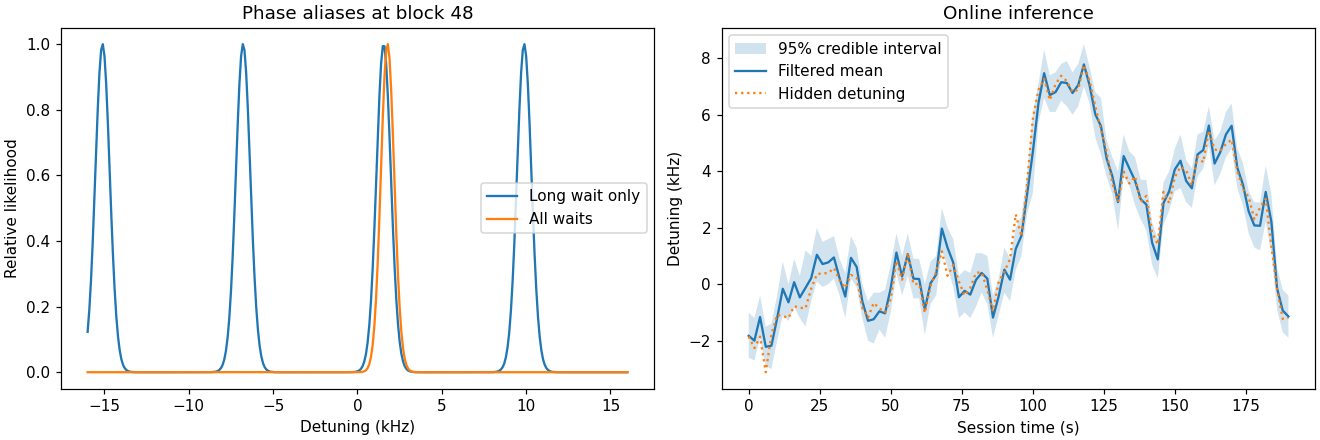

In [5]:
k = blocks//2
fig,ax = plt.subplots(1,2,figsize=(12,4),layout="constrained")
for value,label in [(ll_long,"Long wait only"),(ll,"All waits")]:
    ax[0].plot(grid/1000,np.exp(value[k]-value[k].max()),label=label)
ax[0].set(xlabel="Detuning (kHz)",ylabel="Relative likelihood",title=f"Phase aliases at block {k}")
ax[0].legend()
ax[1].fill_between(times,lo/1000,hi/1000,alpha=.2,label="95% credible interval")
ax[1].plot(times,estimate/1000,label="Filtered mean")
ax[1].plot(times,truth_for_scoring/1000,":",label="Hidden detuning")
ax[1].set(xlabel="Session time (s)",ylabel="Detuning (kHz)",title="Online inference")
ax[1].legend()
plt.show()
print(f"Detuning RMSE: {np.sqrt(np.mean((estimate-truth_for_scoring)**2)):.0f} Hz")
print(f"Single-session interval inclusion: {np.mean((lo<=truth_for_scoring)&(truth_for_scoring<=hi)):.1%}")

## 6. Predict the phase after a correction delay

Propagate the current posterior by $h$ transitions without using future counts. A target with wait $\tau_*$ accumulates phase $\Theta=2\pi f_{k+h}\tau_*$. For a correction $a$, use circular loss $1-\cos(\Theta-a)$, which treats equivalent phases consistently. The minimizing action is the argument of the predictive resultant $E[\exp(i\Theta)\mid\mathcal D_k]$ when this resultant is nonzero. If its magnitude is close to zero, the forecast supplies little directional information.

The comparison includes no correction and a policy based on the current posterior that ignores the delay. Future simulator truth is used only after the decisions are frozen. These losses score statistical policies in the fictional session.

In [6]:
h = forecast_blocks
forecast = posterior[:-h] @ np.linalg.matrix_power(transition,h)
phasor = np.exp(2j*np.pi*target_wait_us*1e-6*grid)
resultant = forecast @ phasor
future_phase = 2*np.pi*target_wait_us*1e-6*truth_for_scoring[h:]
print(f"Forecast horizon: {h*block_spacing_s:g} seconds")
for name,action in [("No correction",0),("Current posterior",np.angle(posterior[:-h]@phasor)),
                    ("Latency-aware forecast",np.angle(resultant))]:
    print(f"{name:24s} mean circular loss = {np.mean(1-np.cos(future_phase-action)):.4f}")
print(f"Mean predictive resultant magnitude: {np.mean(abs(resultant)):.3f}")

Forecast horizon: 6 seconds
No correction            mean circular loss = 0.7816
Current posterior        mean circular loss = 0.3629
Latency-aware forecast   mean circular loss = 0.3425
Mean predictive resultant magnitude: 0.562


## 7. Exercises and extensions

1. **Check the sign.** For small positive detuning, predict whether the sine setting has a larger or smaller ideal zero probability than at zero detuning. Verify with the probability function or Aer counts.
2. **Remove the short wait, then remove the sine phase.** Describe which additional aliases occur. Locate them in the plotted likelihood rather than inferring them from only the posterior mean.
3. **Match budgets.** Allocate the same total shots to one and two waits, then try equal modeled active time. Repeat across seeds and compare detuning RMSE and circular forecast loss.
4. **Reduce calibration shots.** Repeat across independently generated sessions. Compare interval inclusion and consider drawing calibration parameters jointly with detuning as an extension.
5. **Change the forecast horizon and target wait.** Track the magnitude of the predictive resultant and the correction risk. Evaluate when abstention is sensible by charging a fixed cost for correction.
6. **Connect to the proposal's roughness objective.** The present exercise estimates a path and forecasts its future phase. Estimating a Hurst exponent instead uses products of paired-quadrature observations across lags and sensitivities. Use the stored setting metadata to develop that extension.

### Installation and documentation

Install NumPy, SciPy, and Matplotlib in the notebook kernel. For circuit simulation, also install Qiskit 2 and Qiskit Aer. Set the engine to **aer** to require Aer or **analytic** to force the fast baseline.

- [Qiskit Aer simulator guide](https://qiskit.github.io/qiskit-aer/tutorials/1_aersimulator.html)
- [Aer phase damping parameters](https://qiskit.github.io/qiskit-aer/stubs/qiskit_aer.noise.phase_damping_error.html)